# COMP5122M – Data Science Coursework

## Project: Vibe Check - How Gen Z Really Feels About AI



## Team - Shyamin 

### Members: 

Durgam Naga Deeraj Reddy (pvcl0430) ; Harshini Gonela (jklt0901) ; Karuna Anil Gholap (lctl0641) ; Rehan Ali (fnkx0448)



## Group Data Science Analysis

## Project Overview
This project analyses the Pew Research Center's Spring 2025 Global Attitudes Survey to investigate public attitudes towards artificial intelligence across 24 countries.

Task 3 focuses on analysing the generation gap in people's awareness and attitudes towards Artificial Intelligence across different age groups and countries. It answers one central question - "Do younger and older people think differently about AI, and in which countries are those differences largest and smallest?"

The three main areas: 

1. Q30 – AI Awareness (ai_heard)

2. Q31 – AI Attitudes (ai_cncexc)

3. Generation-gap comparison

investigates whether age influences how people understand, perceive and feel about AI across 24 countries, using survey comparisons and statistical evidence.


## Task 3: Generational Gap Analysis

Performed by Harshini Gonela (jklt0901)

### Importing required libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Load the cleaned dataset

In [2]:
# load the cleaned dataset created in Task 1
df = pd.read_csv("Task1_Cleaned_Dataset.csv", low_memory=False)
print("Dataset dimensions:", df.shape)


Dataset dimensions: (28333, 486)


### Check the variables before analysis

The country codes and response codes are interpreted using the supplied Pew data dictionary. Q30/Q31 special responses should already be missing after Task 1. Code 97 in `age` is valid (97 or older), while codes 98 and 99 should have been recoded to missing.

In [3]:
# map the survey country codes to country names
country_names = {
    2: "Canada", 3: "France", 4: "Germany", 5: "Greece", 6: "Hungary",
    7: "Italy", 8: "Netherlands", 9: "Poland", 10: "Spain", 11: "Sweden",
    12: "UK", 13: "Australia", 14: "India", 15: "Indonesia", 16: "Japan",
    17: "South Korea", 18: "Israel", 19: "Turkey", 20: "Kenya",
    21: "Nigeria", 22: "South Africa", 23: "Argentina", 24: "Brazil", 25: "Mexico"
}

# confirm the cleaned data contains the required countries and analysis variables
required_columns = [
    "country", "age", "age_australia", "ai_heard", "ai_cncexc", "weight"
]
assert all(column in df.columns for column in required_columns)
assert df["country"].nunique() == 24
assert not pd.to_numeric(df["age"], errors="coerce").isin([98, 99]).any()
assert set(df["ai_heard"].dropna().unique()).issubset({1, 2, 3})
assert set(df["ai_cncexc"].dropna().unique()).issubset({1, 2, 3})
assert df["weight"].notna().all() and (df["weight"] > 0).all()


### Create comparable age groups

For 22 countries, use the numeric `age` field. For Australia, use the supplied `age_australia` bands. The code combines Australian 50–64 and 65+ into the common 50+ group.

In [4]:
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["age_australia"] = pd.to_numeric(df["age_australia"], errors="coerce")

# numeric age: 18–29, 30–49, and 50+ (including valid code 97 = 97 or older)
df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 29, 49, 120],
    labels=["18–29", "30–49", "50+"],
    right=True
)

# australia has age bands rather than exact ages
australia_age_map = {
    1: "18–29",
    2: "30–49",
    3: "50+",   # 50–64
    4: "50+"    # 65+
}
australia_mask = df["country"].eq(13)
df.loc[australia_mask, "age_group"] = (
    df.loc[australia_mask, "age_australia"].map(australia_age_map)
)

age_order = ["18–29", "30–49", "50+"]
df["age_group"] = pd.Categorical(
    df["age_group"], categories=age_order, ordered=True
)
df["country_name"] = df["country"].map(country_names)

age_group_counts = (
    df.groupby(["country_name", "age_group"], observed=False)
      .size().rename("respondents_with_age_group").reset_index()
)

print("Age-group respondent counts by country:")
display(age_group_counts.pivot(
    index="country_name", columns="age_group",
    values="respondents_with_age_group"
).fillna(0).astype(int))

print("Respondents without a comparable age group:", int(df["age_group"].isna().sum()))

Age-group respondent counts by country:


/var/folders/15/vnzgb5095kj14qn7m2szdjr80000gn/T/ipykernel_15289/713571474.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["age_group"] = pd.cut(
/var/folders/15/vnzgb5095kj14qn7m2szdjr80000gn/T/ipykernel_15289/713571474.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["country_name"] = df["country"].map(country_names)


age_group,18–29,30–49,50+
country_name,,,
Argentina,237,382,384
Australia,326,658,843
Brazil,211,418,473
Canada,102,259,624
France,125,241,652
Germany,119,285,581
Greece,98,340,577
Hungary,80,263,675
India,1083,1499,959


Respondents without a comparable age group: 296


### Calculate weighted Q30 and Q31 distributions

Each country-age-group percentage uses the sum of `weight` for that response category divided by the sum of `weight` across valid responses to the same question in that country-age group. `n_valid` is the unweighted number of respondents contributing to that question's denominator.

In [5]:
Q30_LABELS = {
    1: "A lot",
    2: "A little",
    3: "Nothing at all"
}
Q31_LABELS = {
    1: "More excited than concerned",
    2: "More concerned than excited",
    3: "Equally concerned and excited"
}

def weighted_response_distribution(data, variable, labels, question):
    rows = []
    for (country_code, country_name, age_group), group in data.groupby(
        ["country", "country_name", "age_group"], observed=True
    ):
        valid = group[group[variable].isin(labels.keys()) & group["weight"].notna()].copy()
        denominator_weight = valid["weight"].sum()
        n_valid = len(valid)
        n_age_group = len(group)

        for code, label in labels.items():
            category = valid[valid[variable] == code]
            category_weight = category["weight"].sum()
            weighted_pct = (
                category_weight / denominator_weight * 100
                if denominator_weight > 0 else np.nan
            )
            unweighted_pct = (
                len(category) / n_valid * 100
                if n_valid > 0 else np.nan
            )
            rows.append({
                "question": question,
                "country_code": int(country_code),
                "country": country_name,
                "age_group": str(age_group),
                "response_code": code,
                "response_category": label,
                "n_age_group": n_age_group,
                "n_valid": n_valid,
                "n_missing_for_question": n_age_group - n_valid,
                "weighted_valid_base": denominator_weight,
                "weighted_percentage": weighted_pct,
                "unweighted_percentage": unweighted_pct
            })
    return pd.DataFrame(rows)

q30_results = weighted_response_distribution(
    df, "ai_heard", Q30_LABELS, "Q30 – AI awareness"
)
q31_results = weighted_response_distribution(
    df, "ai_cncexc", Q31_LABELS, "Q31 – AI attitudes"
)

print("Q30 weighted response distributions (first rows):")
display(q30_results.head(12))
print("Q31 weighted response distributions (first rows):")
display(q31_results.head(12))

# confirm that every country-age-group valid-response distribution sums to 100%
for results, question_name in [(q30_results, "Q30"), (q31_results, "Q31")]:
    sums = results.groupby(["country_code", "age_group"])["weighted_percentage"].sum()
    assert np.allclose(sums.values, 100.0, atol=0.01), (
        f"{question_name} distributions do not sum to 100%."
    )

Q30 weighted response distributions (first rows):


,question,country_code,country,age_group,response_code,response_category,n_age_group,n_valid,n_missing_for_question,weighted_valid_base,weighted_percentage,unweighted_percentage
0,Q30 – AI awareness,2,Canada,18–29,1,A lot,102,102,0,173.713480,57.579593,59.803922
1,Q30 – AI awareness,2,Canada,18–29,2,A little,102,102,0,173.713480,36.650053,35.294118
2,Q30 – AI awareness,2,Canada,18–29,3,Nothing at all,102,102,0,173.713480,5.770353,4.901961
3,Q30 – AI awareness,2,Canada,30–49,1,A lot,259,257,2,310.232611,47.231725,51.361868
4,Q30 – AI awareness,2,Canada,30–49,2,A little,259,257,2,310.232611,47.584865,44.747082
5,Q30 – AI awareness,2,Canada,30–49,3,Nothing at all,259,257,2,310.232611,5.183410,3.891051
6,Q30 – AI awareness,2,Canada,50+,1,A lot,614,614,0,491.177812,31.269217,36.319218
7,Q30 – AI awareness,2,Canada,50+,2,A little,614,614,0,491.177812,57.373766,55.374593
8,Q30 – AI awareness,2,Canada,50+,3,Nothing at all,614,614,0,491.177812,11.357017,8.306189
9,Q30 – AI awareness,3,France,18–29,1,A lot,125,125,0,166.351409,77.781656,81.600000


Q31 weighted response distributions (first rows):


,question,country_code,country,age_group,response_code,response_category,n_age_group,n_valid,n_missing_for_question,weighted_valid_base,weighted_percentage,unweighted_percentage
0,Q31 – AI attitudes,2,Canada,18–29,1,More excited than concerned,102,102,0,173.713480,17.063682,18.627451
1,Q31 – AI attitudes,2,Canada,18–29,2,More concerned than excited,102,102,0,173.713480,30.078594,29.411765
2,Q31 – AI attitudes,2,Canada,18–29,3,Equally concerned and excited,102,102,0,173.713480,52.857724,51.960784
3,Q31 – AI attitudes,2,Canada,30–49,1,More excited than concerned,259,255,4,305.259445,9.451901,9.803922
4,Q31 – AI attitudes,2,Canada,30–49,2,More concerned than excited,259,255,4,305.259445,41.322148,38.039216
5,Q31 – AI attitudes,2,Canada,30–49,3,Equally concerned and excited,259,255,4,305.259445,49.225950,52.156863
6,Q31 – AI attitudes,2,Canada,50+,1,More excited than concerned,614,608,6,485.090431,5.972175,7.072368
7,Q31 – AI attitudes,2,Canada,50+,2,More concerned than excited,614,608,6,485.090431,52.050373,47.697368
8,Q31 – AI attitudes,2,Canada,50+,3,Equally concerned and excited,614,608,6,485.090431,41.977452,45.230263
9,Q31 – AI attitudes,3,France,18–29,1,More excited than concerned,125,125,0,166.351409,19.660706,26.400000


### Define and calculate the generation gaps

- **Q30 awareness:** A lot + A little (codes 1 + 2). The gap compares the percentage aware of AI in ages 18–29 with ages 50+.
- **Q31 optimism:** More excited than concerned (code 1). The gap compares this percentage in ages 18–29 with ages 50+.
- **Q31 concern:** More concerned than excited (code 2) is shown as a separate supporting measure.

All gaps are percentage-point differences: younger minus older. The full Q31 distribution, including “Equally concerned and excited”, remains available in `q31_results`.

In [6]:
# convert full response distributions into one row per country-age group
q30_wide = q30_results.pivot_table(
    index=["country_code", "country", "age_group"],
    columns="response_category",
    values="weighted_percentage",
    aggfunc="first"
).reset_index()

q30_wide["AI aware (A lot + A little)"] = (
    q30_wide["A lot"] + q30_wide["A little"]
)

q31_wide = q31_results.pivot_table(
    index=["country_code", "country", "age_group"],
    columns="response_category",
    values="weighted_percentage",
    aggfunc="first"
).reset_index()

gap_rows = []
for country_code, country_name in sorted(country_names.items(), key=lambda x: x[1]):
    q30_country = q30_wide[q30_wide["country_code"] == country_code].set_index("age_group")
    q31_country = q31_wide[q31_wide["country_code"] == country_code].set_index("age_group")
    if not all(group in q30_country.index and group in q31_country.index for group in ["18–29", "50+"]):
        continue

    q30_young = q30_country.loc["18–29", "AI aware (A lot + A little)"]
    q30_old = q30_country.loc["50+", "AI aware (A lot + A little)"]
    q31_excited_young = q31_country.loc["18–29", "More excited than concerned"]
    q31_excited_old = q31_country.loc["50+", "More excited than concerned"]
    q31_concern_young = q31_country.loc["18–29", "More concerned than excited"]
    q31_concern_old = q31_country.loc["50+", "More concerned than excited"]
    q31_equal_young = q31_country.loc["18–29", "Equally concerned and excited"]
    q31_equal_old = q31_country.loc["50+", "Equally concerned and excited"]

    q30_n_young = int(q30_results.loc[
        (q30_results.country_code == country_code) & (q30_results.age_group == "18–29"),
        "n_valid"
    ].iloc[0])
    q30_n_old = int(q30_results.loc[
        (q30_results.country_code == country_code) & (q30_results.age_group == "50+"),
        "n_valid"
    ].iloc[0])
    q31_n_young = int(q31_results.loc[
        (q31_results.country_code == country_code) & (q31_results.age_group == "18–29"),
        "n_valid"
    ].iloc[0])
    q31_n_old = int(q31_results.loc[
        (q31_results.country_code == country_code) & (q31_results.age_group == "50+"),
        "n_valid"
    ].iloc[0])

    gap_rows.append({
        "country_code": country_code,
        "country": country_name,
        "Q30 aware 18–29 (%)": q30_young,
        "Q30 aware 50+ (%)": q30_old,
        "Q30 awareness gap (pp)": q30_young - q30_old,
        "Q30 n 18–29": q30_n_young,
        "Q30 n 50+": q30_n_old,
        "Q31 excited 18–29 (%)": q31_excited_young,
        "Q31 excited 50+ (%)": q31_excited_old,
        "Q31 optimism gap (pp)": q31_excited_young - q31_excited_old,
        "Q31 concerned 18–29 (%)": q31_concern_young,
        "Q31 concerned 50+ (%)": q31_concern_old,
        "Q31 concern gap (pp)": q31_concern_young - q31_concern_old,
        "Q31 equally both 18–29 (%)": q31_equal_young,
        "Q31 equally both 50+ (%)": q31_equal_old,
        "Q31 n 18–29": q31_n_young,
        "Q31 n 50+": q31_n_old
    })

gap_summary = pd.DataFrame(gap_rows).sort_values("country")
display(gap_summary.round(1))

,country_code,country,Q30 aware 18–29 (%),Q30 aware 50+ (%),Q30 awareness gap (pp),Q30 n 18–29,Q30 n 50+,Q31 excited 18–29 (%),Q31 excited 50+ (%),Q31 optimism gap (pp),Q31 concerned 18–29 (%),Q31 concerned 50+ (%),Q31 concern gap (pp),Q31 equally both 18–29 (%),Q31 equally both 50+ (%),Q31 n 18–29,Q31 n 50+
0,23,Argentina,82.1,61.8,20.3,236,381,21.3,10.5,10.8,25.5,55.5,-30.1,53.2,34.0,226,351
1,13,Australia,98.5,96.0,2.5,325,843,16.5,7.4,9.2,44.1,57.4,-13.3,39.3,35.2,325,839
2,24,Brazil,86.4,56.7,29.7,210,416,13.9,7.5,6.4,30.9,65.1,-34.2,55.2,27.5,204,386
3,2,Canada,94.2,88.6,5.6,102,614,17.1,6.0,11.1,30.1,52.1,-22.0,52.9,42.0,102,608
4,3,France,97.8,87.3,10.5,125,629,19.7,9.5,10.1,29.3,42.4,-13.1,51.0,48.0,125,621
5,4,Germany,96.3,94.7,1.7,119,580,22.0,11.4,10.6,21.1,35.5,-14.4,56.9,53.1,119,573
6,5,Greece,99.2,75.4,23.8,98,569,17.5,10.2,7.3,13.9,62.9,-49.0,68.6,26.9,98,553
7,6,Hungary,94.9,89.3,5.7,80,669,26.4,12.6,13.7,23.2,41.1,-17.9,50.5,46.3,80,655
8,14,India,66.2,44.7,21.5,982,784,24.3,20.6,3.7,24.9,27.5,-2.6,50.8,51.9,915,689
9,15,Indonesia,79.2,30.7,48.5,316,202,13.5,19.6,-6.0,31.3,37.1,-5.9,55.2,43.3,309,198


### Identify the largest and smallest gaps

Rank countries by the **absolute size** of the younger-versus-older difference, but retain the signed gap so the direction is clear. A small gap is not necessarily evidence of no age difference; check the valid sample sizes as well.

In [7]:
def show_gap_extremes(data, gap_column, label):
    ranked = data.assign(
        absolute_gap=data[gap_column].abs()
    ).sort_values("absolute_gap", ascending=False)

    largest = ranked.iloc[0]
    smallest = ranked.iloc[-1]

    print(f"\n{label}")
    print(
        f"Largest absolute gap: {largest['country']} = "
        f"{largest[gap_column]:.1f} percentage points "
        f"(18–29 minus 50+)."
    )
    print(
        f"Smallest absolute gap: {smallest['country']} = "
        f"{smallest[gap_column]:.1f} percentage points "
        f"(18–29 minus 50+)."
    )
    return ranked[["country", gap_column, "absolute_gap"]]

q30_gap_ranking = show_gap_extremes(
    gap_summary, "Q30 awareness gap (pp)", "Q30 – AI awareness"
)
q31_gap_ranking = show_gap_extremes(
    gap_summary, "Q31 optimism gap (pp)", "Q31 – More excited than concerned"
)

print("\nCountries where younger adults have higher AI awareness:")
print(int((gap_summary["Q30 awareness gap (pp)"] > 0).sum()), "out of", len(gap_summary))

print("Countries where younger adults are more likely to be more excited than concerned:")
print(int((gap_summary["Q31 optimism gap (pp)"] > 0).sum()), "out of", len(gap_summary))

print("\nCountries ranked by absolute Q30 awareness gap:")
display(q30_gap_ranking.round(1))
print("Countries ranked by absolute Q31 optimism gap:")
display(q31_gap_ranking.round(1))


Q30 – AI awareness
Largest absolute gap: Indonesia = 48.5 percentage points (18–29 minus 50+).
Smallest absolute gap: Germany = 1.7 percentage points (18–29 minus 50+).

Q31 – More excited than concerned
Largest absolute gap: Israel = 34.3 percentage points (18–29 minus 50+).
Smallest absolute gap: Kenya = 2.4 percentage points (18–29 minus 50+).

Countries where younger adults have higher AI awareness:
23 out of 24
Countries where younger adults are more likely to be more excited than concerned:
23 out of 24

Countries ranked by absolute Q30 awareness gap:


,country,Q30 awareness gap (pp),absolute_gap
9,Indonesia,48.5,48.5
22,Turkey,41.6,41.6
19,South Korea,36.6,36.6
14,Mexico,31.3,31.3
2,Brazil,29.7,29.7
16,Nigeria,29.3,29.3
6,Greece,23.8,23.8
13,Kenya,22.9,22.9
8,India,21.5,21.5
0,Argentina,20.3,20.3


Countries ranked by absolute Q31 optimism gap:


,country,Q31 optimism gap (pp),absolute_gap
10,Israel,34.3,34.3
20,Spain,26.7,26.7
11,Italy,20.5,20.5
17,Poland,19.8,19.8
12,Japan,18.6,18.6
19,South Korea,16.8,16.8
15,Netherlands,16.2,16.2
7,Hungary,13.7,13.7
3,Canada,11.1,11.1
0,Argentina,10.8,10.8


### Check the effect of weighting and the age boundary

This check compares the selected 18–29 versus 50+ gap with an unweighted version and an alternative 18–29 versus 30+ gap. The 30+ percentage is pooled using its valid respondent counts or survey-weight totals, rather than averaging the two age-group percentages. These are descriptive comparisons and are not statistical significance tests.

In [8]:
# calculate one response percentage across one or more age groups
def response_rate(results, country, age_groups, categories, weighted=True):
    selected = results[
        results["country"].eq(country)
        & results["age_group"].isin(age_groups)
    ]

    bases = selected[["age_group", "weighted_valid_base", "n_valid"]].drop_duplicates()
    denominator = (
        bases["weighted_valid_base"].sum()
        if weighted else bases["n_valid"].sum()
    )

    selected = selected[selected["response_category"].isin(categories)]
    if weighted:
        numerator = (
            selected["weighted_percentage"] * selected["weighted_valid_base"] / 100
        ).sum()
    else:
        numerator = (
            selected["unweighted_percentage"] * selected["n_valid"] / 100
        ).sum()

    return numerator / denominator * 100 if denominator else np.nan


# compare weighted results with unweighted results and an alternative 30+ age group
sensitivity_rows = []

for country in sorted(gap_summary["country"].unique()):
    row = {"country": country}

    for question, results, categories in [
        ("Q30", q30_results, ["A lot", "A little"]),
        ("Q31", q31_results, ["More excited than concerned"])
    ]:
        young_weighted = response_rate(results, country, ["18–29"], categories)
        older_weighted = response_rate(results, country, ["50+"], categories)
        young_unweighted = response_rate(
            results, country, ["18–29"], categories, weighted=False
        )
        older_unweighted = response_rate(
            results, country, ["50+"], categories, weighted=False
        )
        older_30plus = response_rate(
            results, country, ["30–49", "50+"], categories
        )

        row[f"{question} weighted gap 18–29 vs 50+ (pp)"] = young_weighted - older_weighted
        row[f"{question} unweighted gap 18–29 vs 50+ (pp)"] = young_unweighted - older_unweighted
        row[f"{question} weighted gap 18–29 vs 30+ (pp)"] = young_weighted - older_30plus

    sensitivity_rows.append(row)

sensitivity_summary = pd.DataFrame(sensitivity_rows)

for question in ["Q30", "Q31"]:
    sensitivity_summary[f"{question} weighting effect (pp)"] = (
        sensitivity_summary[f"{question} unweighted gap 18–29 vs 50+ (pp)"]
        - sensitivity_summary[f"{question} weighted gap 18–29 vs 50+ (pp)"]
    )
    sensitivity_summary[f"{question} age-boundary effect (pp)"] = (
        sensitivity_summary[f"{question} weighted gap 18–29 vs 30+ (pp)"]
        - sensitivity_summary[f"{question} weighted gap 18–29 vs 50+ (pp)"]
    )

display(sensitivity_summary.round(1))


,country,Q30 weighted gap 18–29 vs 50+ (pp),Q30 unweighted gap 18–29 vs 50+ (pp),Q30 weighted gap 18–29 vs 30+ (pp),Q31 weighted gap 18–29 vs 50+ (pp),Q31 unweighted gap 18–29 vs 50+ (pp),Q31 weighted gap 18–29 vs 30+ (pp),Q30 weighting effect (pp),Q30 age-boundary effect (pp),Q31 weighting effect (pp),Q31 age-boundary effect (pp)
0,Argentina,20.3,17.2,13.0,10.8,9.4,10.2,-3.1,-7.3,-1.4,-0.7
1,Australia,2.5,2.3,1.6,9.2,9.3,4.8,-0.2,-0.9,0.2,-4.4
2,Brazil,29.7,28.5,22.4,6.4,5.2,4.7,-1.2,-7.3,-1.2,-1.7
3,Canada,5.6,3.4,3.2,11.1,11.6,9.7,-2.2,-2.4,0.5,-1.3
4,France,10.5,7.0,7.5,10.1,17.1,6.0,-3.5,-3.0,6.9,-4.2
5,Germany,1.7,1.6,-0.1,10.6,9.8,5.1,-0.0,-1.7,-0.8,-5.5
6,Greece,23.8,11.8,18.7,7.3,11.4,7.7,-12.0,-5.1,4.1,0.4
7,Hungary,5.7,3.6,4.0,13.7,13.0,9.2,-2.1,-1.7,-0.7,-4.5
8,India,21.5,14.5,15.4,3.7,2.0,3.5,-6.9,-6.0,-1.7,-0.2
9,Indonesia,48.5,41.9,32.9,-6.0,-2.6,-1.5,-6.5,-15.5,3.4,4.5


### Visualise the cross-country results

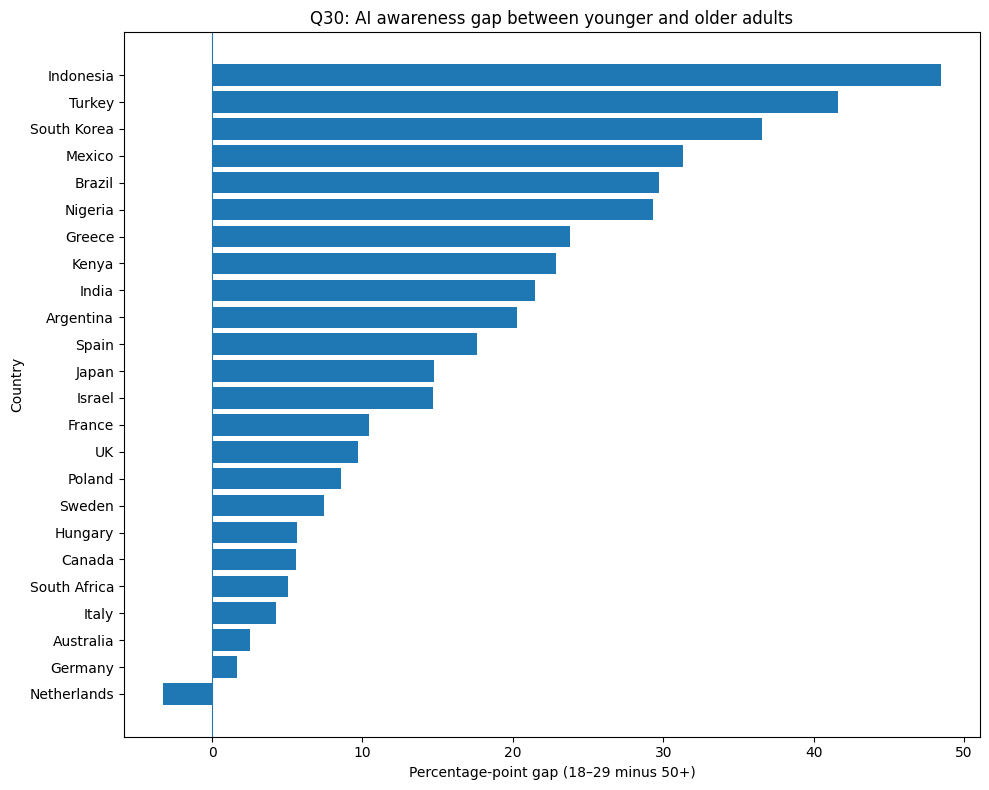

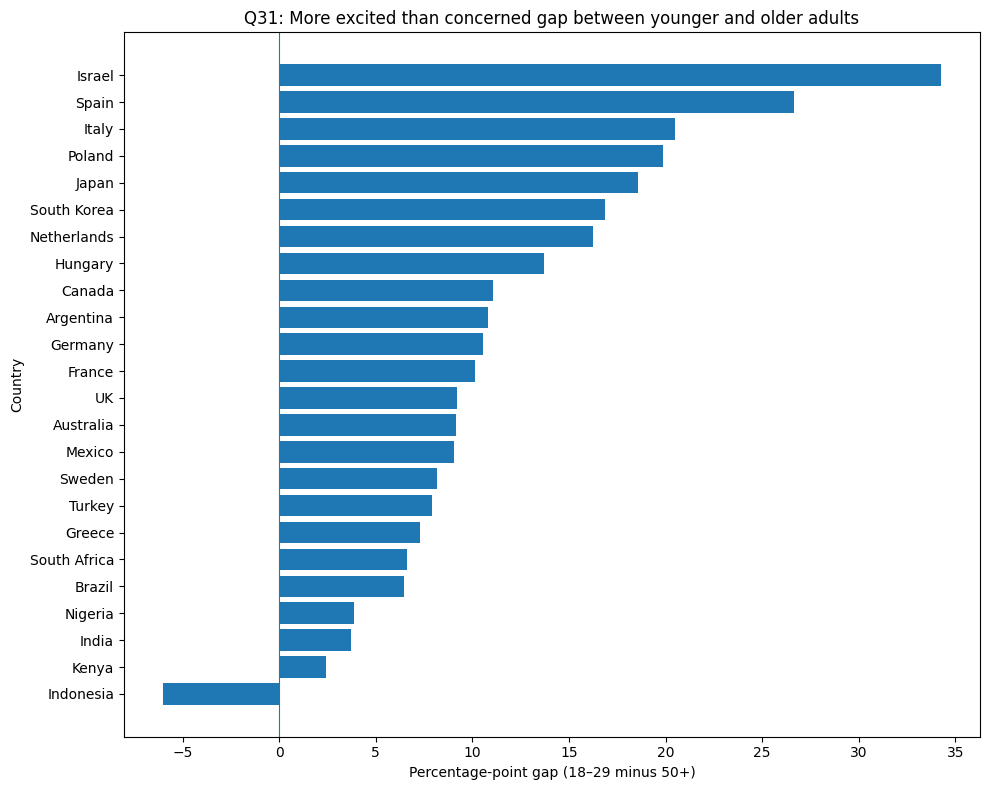

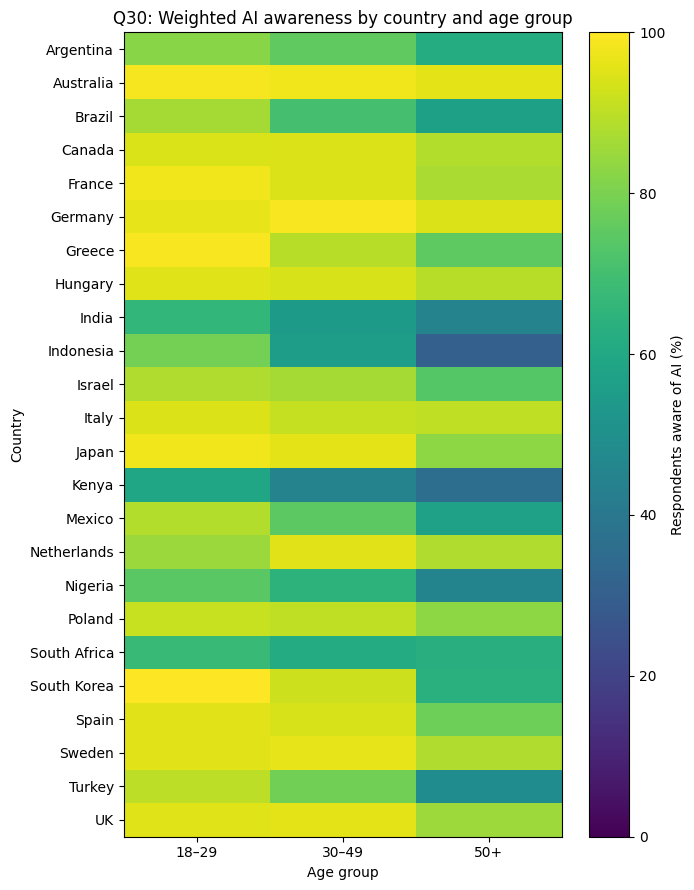

In [9]:
# chart 1: Q30 awareness gap across all countries
plot_q30 = gap_summary.sort_values("Q30 awareness gap (pp)")
plt.figure(figsize=(10, 8))
plt.barh(plot_q30["country"], plot_q30["Q30 awareness gap (pp)"])
plt.axvline(0, linewidth=0.8)
plt.xlabel("Percentage-point gap (18–29 minus 50+)")
plt.ylabel("Country")
plt.title("Q30: AI awareness gap between younger and older adults")
plt.tight_layout()
plt.savefig("Task3_Q30_Awareness_Gap.png", dpi=180, bbox_inches="tight")
plt.show()

# chart 2: Q31 optimism gap across all countries
plot_q31 = gap_summary.sort_values("Q31 optimism gap (pp)")
plt.figure(figsize=(10, 8))
plt.barh(plot_q31["country"], plot_q31["Q31 optimism gap (pp)"])
plt.axvline(0, linewidth=0.8)
plt.xlabel("Percentage-point gap (18–29 minus 50+)")
plt.ylabel("Country")
plt.title("Q31: More excited than concerned gap between younger and older adults")
plt.tight_layout()
plt.savefig("Task3_Q31_Optimism_Gap.png", dpi=180, bbox_inches="tight")
plt.show()

# chart 3: Q30 weighted awareness by age group and country (heatmap)
heat = q30_wide.pivot(
    index="country", columns="age_group",
    values="AI aware (A lot + A little)"
).reindex(columns=age_order)
plt.figure(figsize=(7, 9))
image = plt.imshow(heat.values, aspect="auto", vmin=0, vmax=100)
plt.colorbar(image, label="Respondents aware of AI (%)")
plt.xticks(range(len(heat.columns)), heat.columns)
plt.yticks(range(len(heat.index)), heat.index)
plt.xlabel("Age group")
plt.ylabel("Country")
plt.title("Q30: Weighted AI awareness by country and age group")
plt.tight_layout()
plt.savefig("Task3_Q30_Awareness_Heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

### Inspect the full Q31 distribution

This chart retains all three substantive Q31 categories. Israel has the largest Q31 optimism gap, Kenya the smallest, and Indonesia is an exception where the older group has the higher “more excited” percentage. These selected countries illustrate the range of patterns; the complete results for all countries remain in `q31_results`.

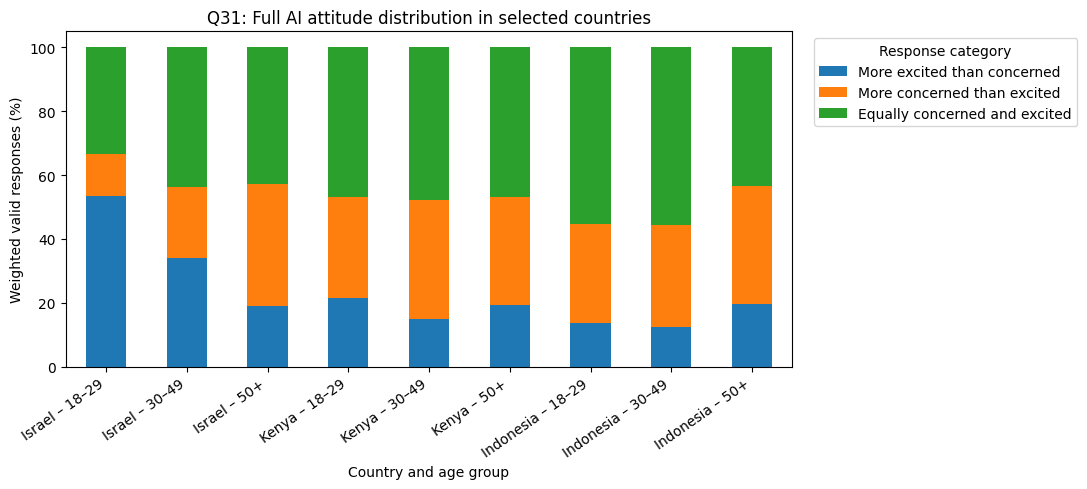

In [10]:
selected_countries = ["Israel", "Kenya", "Indonesia"]
selected_q31 = q31_results[q31_results["country"].isin(selected_countries)].copy()

selected_q31["country_age"] = (
    selected_q31["country"] + " – " + selected_q31["age_group"]
)
stacked = selected_q31.pivot_table(
    index="country_age",
    columns="response_category",
    values="weighted_percentage",
    aggfunc="first"
)
category_order = [
    "More excited than concerned",
    "More concerned than excited",
    "Equally concerned and excited"
]
stacked = stacked[category_order]

# keep the display order country first, then age group
ordered_index = [
    f"{country} – {age}" for country in selected_countries for age in age_order
]
stacked = stacked.reindex(ordered_index)

ax = stacked.plot(kind="bar", stacked=True, figsize=(11, 5))
ax.set_ylabel("Weighted valid responses (%)")
ax.set_xlabel("Country and age group")
ax.set_title("Q31: Full AI attitude distribution in selected countries")
ax.legend(title="Response category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("Task3_Q31_Selected_Distributions.png", dpi=180, bbox_inches="tight")
plt.show()

### Findings and interpretation

In [11]:
# concise, data-driven findings for the report handover
q30_largest = gap_summary.loc[gap_summary["Q30 awareness gap (pp)"].abs().idxmax()]
q30_smallest = gap_summary.loc[gap_summary["Q30 awareness gap (pp)"].abs().idxmin()]
q31_largest = gap_summary.loc[gap_summary["Q31 optimism gap (pp)"].abs().idxmax()]
q31_smallest = gap_summary.loc[gap_summary["Q31 optimism gap (pp)"].abs().idxmin()]
q30_positive = int((gap_summary["Q30 awareness gap (pp)"] > 0).sum())
q31_positive = int((gap_summary["Q31 optimism gap (pp)"] > 0).sum())
q31_negative = int((gap_summary["Q31 optimism gap (pp)"] < 0).sum())
concern_older_higher = int((gap_summary["Q31 concern gap (pp)"] < 0).sum())
concern_younger_higher = int((gap_summary["Q31 concern gap (pp)"] > 0).sum())

print("TASK 3 FINDINGS")
print(f"Q30: Younger adults have higher AI awareness in {q30_positive} of {len(gap_summary)} countries.")
print(
    f"Largest absolute Q30 gap: {q30_largest['country']} "
    f"({q30_largest['Q30 awareness gap (pp)']:.1f} pp)."
)
print(
    f"Smallest absolute Q30 gap: {q30_smallest['country']} "
    f"({q30_smallest['Q30 awareness gap (pp)']:.1f} pp)."
)
print(f"Q31: Younger adults are more likely to say 'more excited than concerned' in {q31_positive} countries; older adults are higher in {q31_negative} country.")
print(
    f"Largest absolute Q31 optimism gap: {q31_largest['country']} "
    f"({q31_largest['Q31 optimism gap (pp)']:.1f} pp)."
)
print(
    f"Smallest absolute Q31 optimism gap: {q31_smallest['country']} "
    f"({q31_smallest['Q31 optimism gap (pp)']:.1f} pp)."
)
print(
    f"Q31 concern: older adults are more likely to be concerned in {concern_older_higher} countries; "
    f"younger adults are higher in {concern_younger_higher} countries."
)
print("Countries where younger adults report more concern:", 
      gap_summary.loc[gap_summary["Q31 concern gap (pp)"] > 0, "country"].tolist())

print("\nImportant sample-size checks for the extreme countries:")
display(gap_summary[
    gap_summary["country"].isin([
        q30_largest["country"], q30_smallest["country"],
        q31_largest["country"], q31_smallest["country"]
    ])
][[
    "country", "Q30 n 18–29", "Q30 n 50+",
    "Q31 n 18–29", "Q31 n 50+",
    "Q30 awareness gap (pp)", "Q31 optimism gap (pp)"
]].round(1))

TASK 3 FINDINGS
Q30: Younger adults have higher AI awareness in 23 of 24 countries.
Largest absolute Q30 gap: Indonesia (48.5 pp).
Smallest absolute Q30 gap: Germany (1.7 pp).
Q31: Younger adults are more likely to say 'more excited than concerned' in 23 countries; older adults are higher in 1 country.
Largest absolute Q31 optimism gap: Israel (34.3 pp).
Smallest absolute Q31 optimism gap: Kenya (2.4 pp).
Q31 concern: older adults are more likely to be concerned in 22 countries; younger adults are higher in 2 countries.
Countries where younger adults report more concern: ['South Korea', 'Turkey']

Important sample-size checks for the extreme countries:


,country,Q30 n 18–29,Q30 n 50+,Q31 n 18–29,Q31 n 50+,Q30 awareness gap (pp),Q31 optimism gap (pp)
5,Germany,119,580,119,573,1.7,10.6
9,Indonesia,316,202,309,198,48.5,-6.0
10,Israel,234,399,217,300,14.7,34.3
13,Kenya,555,104,537,97,22.9,2.4




### Export outputs for Task 4

The two CSV files below provide Task 4 with the full age-group response distributions and the country-level gap summary. The charts are also saved as PNG files in the notebook's working directory.

In [12]:
# save the results needed for the report
q30_results.to_csv("Task3_Q30_Age_Group_Distributions.csv", index=False)
q31_results.to_csv("Task3_Q31_Age_Group_Distributions.csv", index=False)
gap_summary.to_csv("Task3_Country_Gap_Summary.csv", index=False)
sensitivity_summary.to_csv("Task3_Sensitivity_Analysis.csv", index=False)
